In [ ]:
import os
import torch
from matplotlib import pyplot as plt
from time import time
from tensordict import TensorDict
from mdml_sim.lorenz96 import L96Simulator
os.chdir('..')
from adda.system.state import State
from adda.observation.operators import random_sparse_noisy_obs
from adda.probability.distributions import DiagonalGaussian
from adda.util.initialization import naive_initialization
from adda.util.visualization import show_1dseqimg, plot_ensemble_analysis
# Import the 4D-Var parameter tuning functions
from adda.pt.variational import sc4dvar_single_window_pt, wc4dvar_single_window_pt

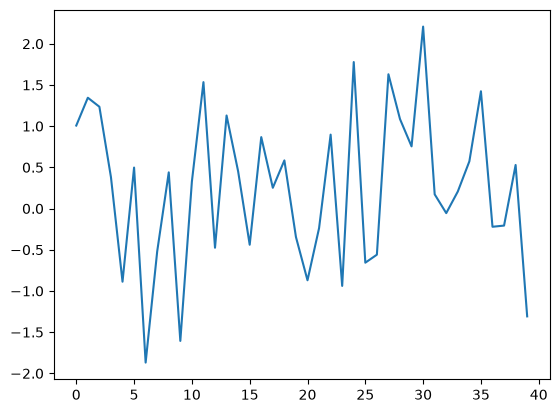

In [ ]:
# Define a target initial state
n_variables = 40 # N = 40
initial_state = State(torch.randn(1, 1, n_variables))  # (batch, time, n_variables)
plt.plot(initial_state.fields['x'].squeeze())

True forcing parameter: 6.62394917011261
torch.Size([1200, 40])


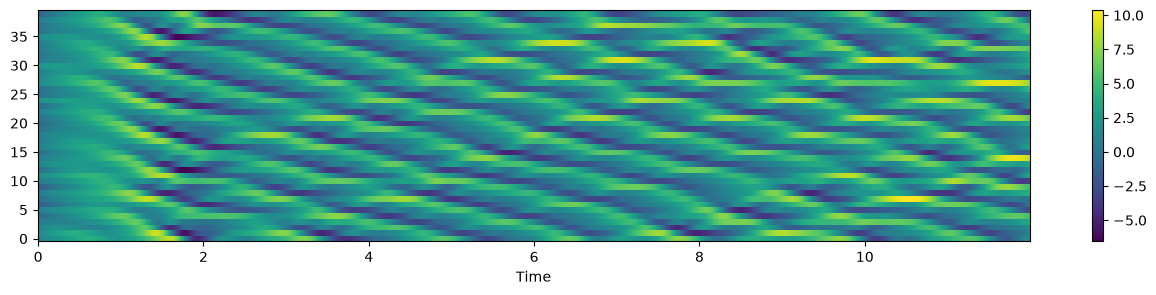

In [ ]:
# Generate a time series from the defined initial_condition using our L96 simulator
forcing = 8.0 + torch.randn(1).item() # Sample F
print(f'True forcing parameter: {forcing}')
forward_operator_true = L96Simulator(forcing=forcing)
ts_length = 1200
time_step = 0.01 # one time step = 0.01 second
forecast_steps = torch.arange(0, ts_length * time_step, time_step)
ts = forward_operator_true.integrate(time=forecast_steps, state=initial_state.fields['x'].reshape(1, -1)).squeeze()

print(ts.shape)
show_1dseqimg(ts.T, dt=time_step, x_label="Time")

In [ ]:
cutoff_time = 4
cutoff_index = int(cutoff_time / time_step)
true_ts = ts[cutoff_index:]
true_initial_state = true_ts[0]
forecast_steps = torch.arange(0, ts_length * time_step - cutoff_time, time_step)

true_ts = State(true_ts.reshape(1, -1, n_variables), time_axis=forecast_steps)

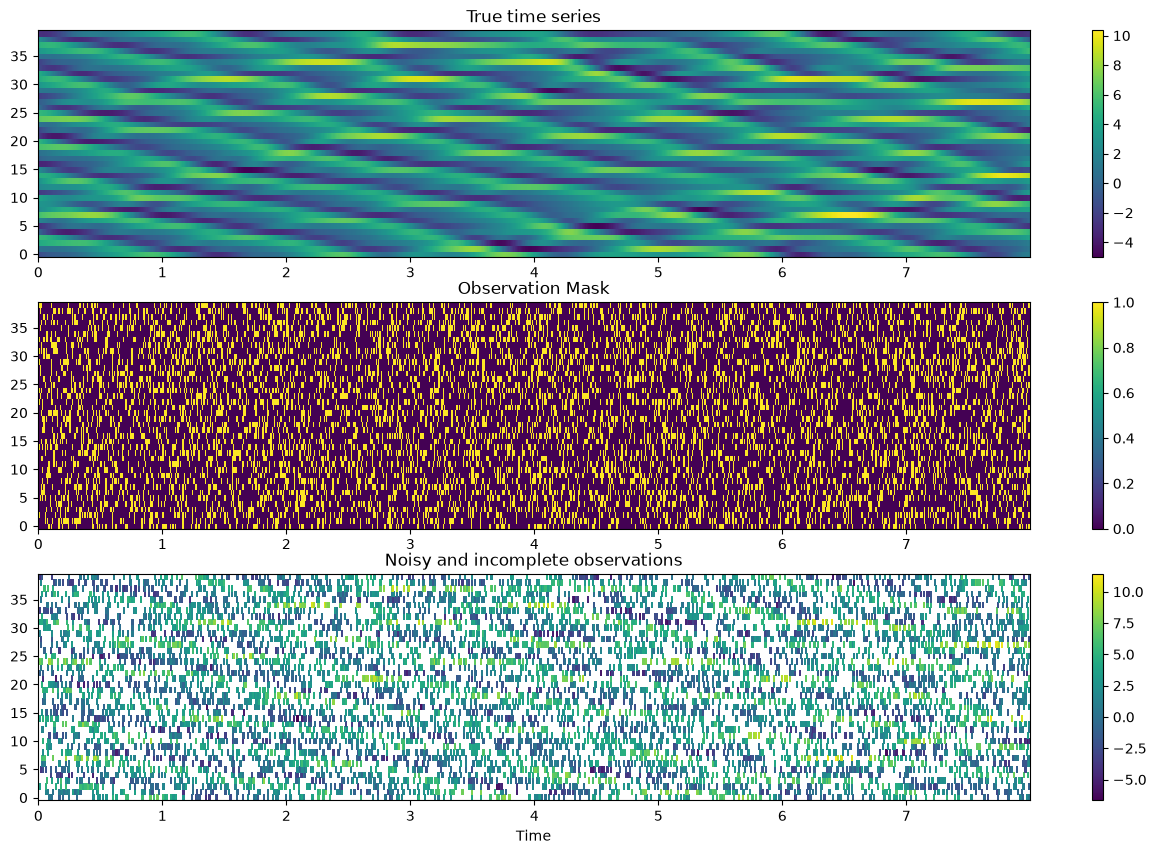

In [ ]:
noise_amplitude = 1.0  # observation noise s.d.
p_obs = 0.25 # 75% of the variables are masked

groundtruth, obs_op, observations = random_sparse_noisy_obs(true_ts, noise_amplitude, p_obs)

valid_obs = observations.state.fields['x'][0].T
valid_obs[torch.logical_not(observations.mask.fields['x'][0].T)] = torch.nan

fig, ax = plt.subplots(3, 1, figsize=(16,10))

show_1dseqimg(true_ts.fields['x'][0].T, dt=time_step, ax=ax[0], title="True time series")
show_1dseqimg(observations.mask.fields['x'][0].T, dt=time_step, ax=ax[1], title="Observation Mask")
show_1dseqimg(valid_obs, dt=time_step, ax=ax[2], title="Noisy and incomplete observations", x_label="Time")

In [ ]:
# we define a simple one-time-step function in order to fit the ADDA conventions
# In order to use a parameter tuning function, you should always have a function like this taking the state, dt, dynamic_inputs, static_inputs and parameters

def next_step_function(x: torch.Tensor, dt: float, dynamic_inputs: State, static_inputs: State, parameters: State):
    B, T = x.fields.batch_size[:2]
    x_tensor = x.fields.reshape(-1)["x"]  # combine batch and time dimensions, leave others intact
    forward_operator = L96Simulator(forcing=parameters.fields['x'].squeeze().expand(x_tensor.shape).squeeze(1), use_adjoint=False)
    integrated = forward_operator.integrate(torch.arange(2) * dt, x_tensor)[:, 1] # integrate over a time step, take the current time
    integrated = integrated.unsqueeze(0) # re-add batch dimension
    new_fields = TensorDict(x=integrated, batch_size=(1, T))
    return State(new_fields)  # return State object, advancing time

# Strong-constraint 4D-Var parameter tuning

In [ ]:
n_obs_steps = 80 # we assimilate only on the earliest time steps, otherwise the optimization would be too unstable
time_window = (observations.state.time_axis[0], observations.state.time_axis[n_obs_steps])

obs_op_opt = obs_op.restrict_time_domain(*time_window)
observations_opt = observations.restrict_time_domain(*time_window)

print(obs_op.mask.fields)

TensorDict(
    fields={
        x: Tensor(shape=torch.Size([1, 800, 40]), device=cpu, dtype=torch.bool, is_shared=False)},
    batch_size=torch.Size([1, 800]),
    device=None,
    is_shared=False)


In [ ]:
initialization = naive_initialization(observations)  # state estimate for all time points
initialization = initialization[:,:1]  # first time point only
parameter_init = State(torch.Tensor([8.0]).reshape(1,1,1)).clone().requires_grad_()
param_prior = DiagonalGaussian(torch.Tensor([8.0]), torch.Tensor([1.0]))

In [ ]:
t0 = time()
assimilated_ic, assimilated_params = sc4dvar_single_window_pt(next_step_function, 
                                                              observations_opt, 
                                                              obs_op_opt, 
                                                              initialization,  
                                                              parameter_init,
                                                              param_prior=param_prior,
                                                              optimizer_pars={'lr': 1e-1})                                     
print(f'Total time for the 4D-Var optimization: {time() - t0} seconds')

Total time for the 4D-Var optimization: 5.954219579696655 seconds


Initial guess MSE: 1.0779688358306885
Assimilated state MSE: 0.12212667614221573


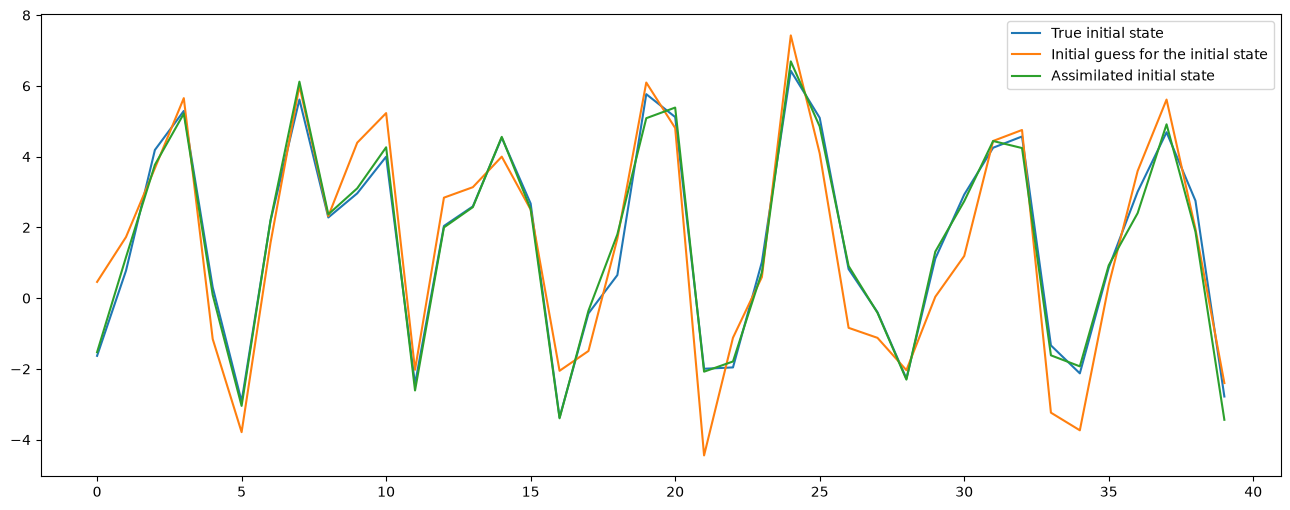

In [ ]:
plt.figure(figsize=(16,6))
plt.plot(true_initial_state, label='True initial state')
plt.plot(initialization.fields['x'].squeeze(), label='Initial guess for the initial state')
plt.plot(assimilated_ic.fields['x'].squeeze().detach(), label='Assimilated initial state')
plt.legend()

MSE0 = torch.mean((initialization.fields['x'].squeeze() - true_initial_state) **2)
MSE = torch.mean((assimilated_ic.fields['x'].squeeze() - true_initial_state) **2)

print(f'Initial guess MSE: {MSE0}')
print(f'Assimilated state MSE: {MSE}')

In [ ]:
assimilated_forcing = assimilated_params.fields['x'].item()
print(f"True forcing: {forcing}, estimated forcing: {assimilated_forcing}")

True forcing: 6.62394917011261, estimated forcing: 6.567934036254883


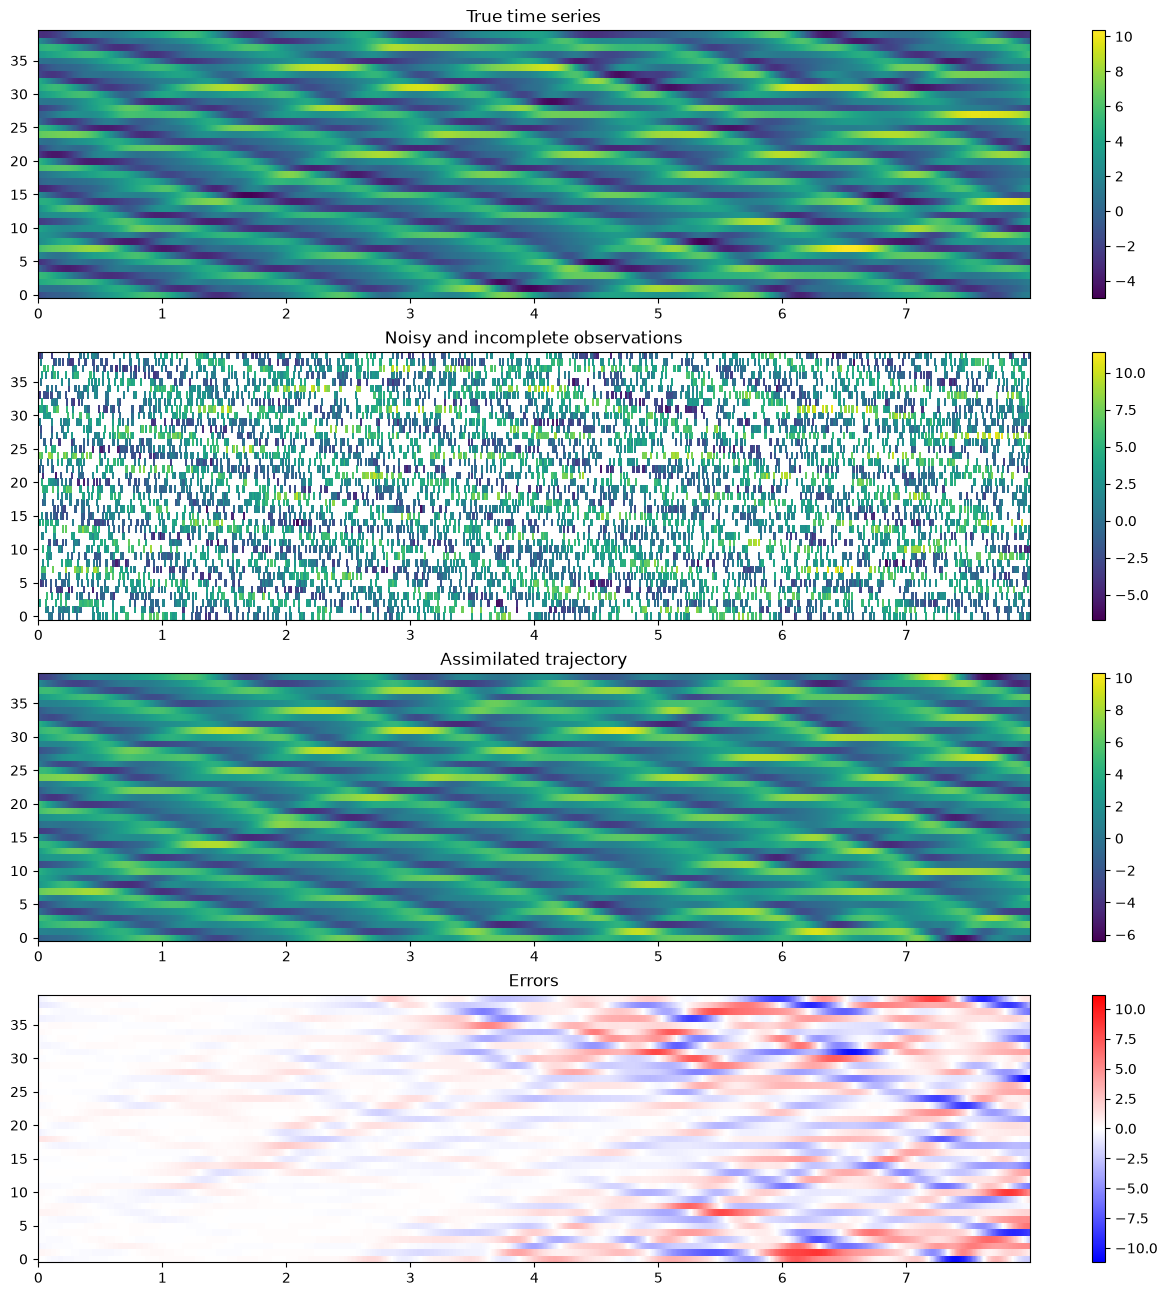

In [ ]:
# rollout from assimilated state
forward_operator = L96Simulator(forcing=assimilated_forcing)
assimilated_trajectory = forward_operator.integrate(time=forecast_steps, state=assimilated_ic.fields['x'][0]).squeeze().cpu().detach()
errors = (assimilated_trajectory - true_ts.fields['x'].squeeze())

fig, ax = plt.subplots(4, 1, figsize=(16,16))
show_1dseqimg(true_ts.fields['x'][0].T, dt=time_step, ax=ax[0], title="True time series")
show_1dseqimg(valid_obs, dt=time_step, ax=ax[1], title="Noisy and incomplete observations")
show_1dseqimg(assimilated_trajectory.T, dt=time_step, ax=ax[2], title="Assimilated trajectory")
show_1dseqimg(errors.T, dt=time_step, ax=ax[3], title="Errors", cmap="bwr", center_on_zero=True)

# Weak-constraint 4D-Var parameter tuning

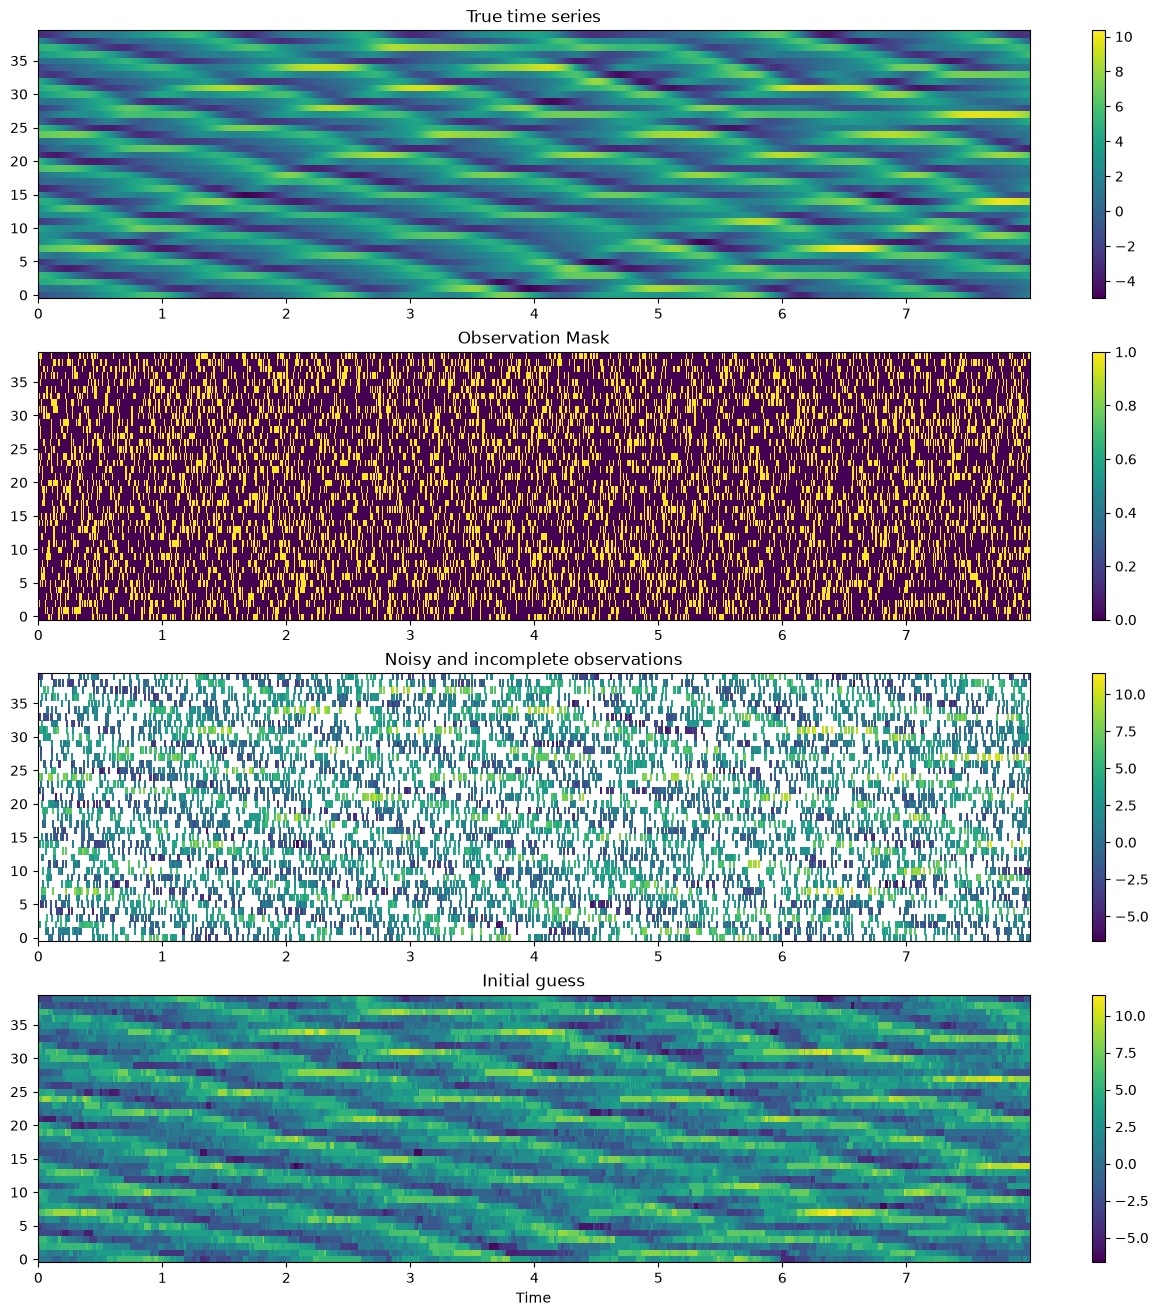

In [ ]:
# we build an initial guess for the initial state, using the available observations
# We simply use the first available observation for each channel
initialization = naive_initialization(observations)  # state estimate for all time points

fig, ax = plt.subplots(4, 1, figsize=(16,16))

show_1dseqimg(true_ts.fields['x'][0].T, dt=time_step, ax=ax[0], title="True time series")
show_1dseqimg(observations.mask.fields['x'][0].T, dt=time_step, ax=ax[1], title="Observation Mask")
show_1dseqimg(valid_obs, dt=time_step, ax=ax[2], title="Noisy and incomplete observations")
show_1dseqimg(initialization.fields['x'][0].T, dt=time_step, ax=ax[3], title="Initial guess", x_label="Time")

In [ ]:
n_steps = true_ts.time_axis.nelement()

model_error_distribs = DiagonalGaussian(torch.zeros(1, n_steps - 1, n_variables), 
                                        torch.ones(1, n_steps - 1, n_variables))

parameter_init = State(torch.Tensor([8.0]).reshape(1,1,1)).clone().requires_grad_()
param_prior = DiagonalGaussian(torch.Tensor([8.0]), torch.Tensor([1.0]))

In [ ]:
t0 = time()
assimilated_states, assimilated_params = wc4dvar_single_window_pt(next_step_function, 
                                              observations, 
                                              obs_op, 
                                              model_error_distribs,
                                              x_init=initialization, 
                                              param_init=parameter_init,
                                              param_prior=param_prior,
                                              optimizer_pars={'lr': 1},
                                              alpha=1e4,
                                              n_steps=50,
                                              verbose=0)                                       
print(f'Total time for the 4D-Var optimization: {time() - t0} seconds')

assimilated_states = assimilated_states.detach()

Total time for the 4D-Var optimization: 10.479034423828125 seconds


In [ ]:
assimilated_forcing = assimilated_params.fields['x'].item()
print(f"True forcing: {forcing}, estimated forcing: {assimilated_forcing}")

True forcing: 6.62394917011261, estimated forcing: 6.626400470733643


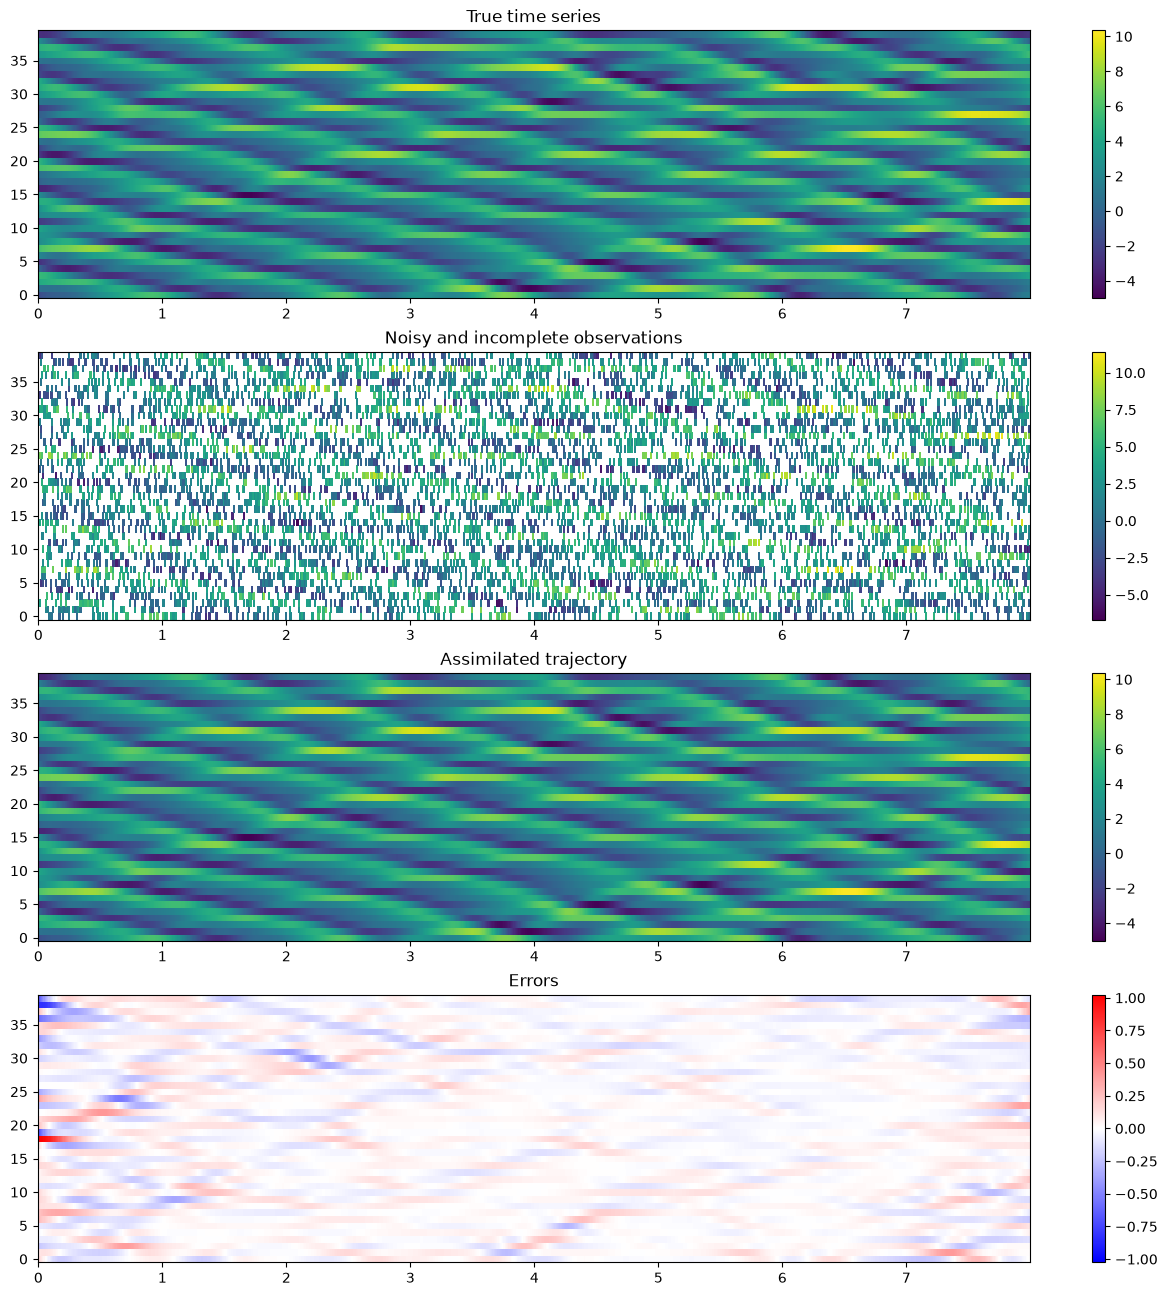

In [ ]:


assimilated_trajectory = assimilated_states.fields['x'][0]
errors = (assimilated_trajectory - true_ts.fields['x'].squeeze())

fig, ax = plt.subplots(4, 1, figsize=(16,16))
show_1dseqimg(true_ts.fields['x'][0].T, dt=time_step, ax=ax[0], title="True time series")
show_1dseqimg(valid_obs, dt=time_step, ax=ax[1], title="Noisy and incomplete observations")
show_1dseqimg(assimilated_trajectory.T, dt=time_step, ax=ax[2], title="Assimilated trajectory")
show_1dseqimg(errors.T, dt=time_step, ax=ax[3], title="Errors", cmap="bwr", center_on_zero=True)